# DLA analysis · JEPA-Vicuna vs LLaVA-1.5 · POPE object hallucination (CPU only)

Inputs (Add data): **`dla-jepa-vicuna`** (your cache), **`dla-llava`** (Rohan's cache), **`vlm-questions`** (question text, optional), COCO val2014 (example images, optional). No GPU, no model download.

1. **Outcome-split statistics**: for every component (embed, 1024 heads, 32 MLPs) compare correct vs hallucinated answers with Welch t / Cohen d / BH-FDR (paper criterion: padj < 0.05 and |d| > 0.3). Three contrasts: object absent (TN vs FP), object present (TP vs FN), pooled.
1b. **Does averaging hide per-question structure?** Levene variance test and variance-share decomposition (which components drive the spread of the answer logit, not just its mean).
2. **Paired comparison with LLaVA** on the same question ids: agreement, where the net-bias gap comes from, per-component correlation, and the questions where one model is right and the other wrong.
5. **High-margin subset**: repeat step 1 on confident answers only.

Sign convention: every contribution is multiplied by +1 if the correct answer is "yes" and -1 if it is "no", so a positive value always means "pushes towards the correct answer". Cohen d > 0 = the component supports the correct answer more in correct samples (grounding-like); d < 0 = it supports the correct answer less when the model is wrong (hallucination-like). Contributions are in logit units (divided by rms).

Outputs go to `/kaggle/working/analysis` (CSVs, plots, and `candidates.json` for the ablation notebook).

In [1]:
# 1. CONFIG
import os, re, glob, json, math, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from collections import Counter
from scipy import stats

INPUT_ROOT   = "/kaggle/input"
HALLUC_TYPE  = "object"
OURS_SLUG    = "dla-jepa-vicuna"
LLAVA_SLUG   = "dla-llava"
OUT_DIR      = "/kaggle/working/analysis"
ALPHA, D_MIN = 0.05, 0.3          # paper criterion
MARGIN_Q     = 0.5                # step 5: keep the most confident (1 - MARGIN_Q) fraction by |logit diff|
TOPK         = 12
os.makedirs(OUT_DIR, exist_ok=True)
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

In [2]:
# 2. LOAD CACHES
def find_dir(slug):
    hits = sorted({os.path.dirname(p) for p in glob.glob(f"{INPUT_ROOT}/**/{slug}/{HALLUC_TYPE}_batch_*.pt", recursive=True)})
    assert hits, f"no {HALLUC_TYPE}_batch_*.pt under a folder named {slug}: add the dataset as input"
    return hits[0]

def load_cache(d):
    files = sorted(glob.glob(f"{d}/{HALLUC_TYPE}_batch_*.pt"), key=lambda f: int(re.findall(r"_batch_(\d+)\.pt$", f)[0]))
    ents = [e for f in files for e in torch.load(f, weights_only=False)]
    rms = np.array([float(e["rms"]) for e in ents])
    D = dict(
        qid=np.array([e["question_id"] for e in ents]),
        image_id=np.array([str(e["image_id"]) for e in ents]),
        gt=np.array([str(e["ground_truth_answer"]).strip().lower() for e in ents]),
        rms=rms, ld=np.array([float(e["logit_diff"]) for e in ents]),
        emb=np.array([float(e["embed"]) for e in ents]) / rms,
        attn=np.stack([np.asarray(e["attn"], dtype=np.float64) for e in ents]) / rms[:, None, None],   # (N, layer, head)
        mlp=np.stack([np.asarray(e["mlp"], dtype=np.float64) for e in ents]) / rms[:, None])           # (N, layer)
    err = np.abs(D["emb"] + D["attn"].sum((1, 2)) + D["mlp"].sum(1) - D["ld"]).max()
    print(f"{d}: {len(ents)} entries | max |sum(components) - logit_diff| = {err:.4f}")
    assert err < 0.5
    return D

def take(D, idx): return {k: v[idx] for k, v in D.items()}

O = load_cache(find_dir(OURS_SLUG))
try: L = load_cache(find_dir(LLAVA_SLUG))
except AssertionError as e: L = None; print("LLaVA cache not found, step 2 will be skipped:", e)
N_LAYER, N_HEAD = O["attn"].shape[1:]

def add_outcomes(D):
    D["pred"] = np.where(D["ld"] > 0, "yes", "no")          # sign of the Yes-No logit difference (what DLA decomposes)
    D["correct"] = D["pred"] == D["gt"]
    D["outcome"] = np.where((D["gt"] == "yes") & (D["pred"] == "yes"), "TP",
                   np.where((D["gt"] == "no") & (D["pred"] == "no"), "TN", np.where(D["pred"] == "yes", "FP", "FN")))
def summary(name, D):
    c = Counter(D["outcome"])
    print(f"{name:12s} n={len(D['gt'])} | acc {D['correct'].mean():.3f} | yes-rate {(D['pred'] == 'yes').mean():.3f} | mean logit diff {D['ld'].mean():+.3f} | "
          f"TP {c['TP']} TN {c['TN']} FP(hallucination) {c['FP']} FN {c['FN']}")
add_outcomes(O); summary("ours", O)
if L is not None:
    idx = {q: i for i, q in enumerate(L["qid"])}
    keep = [i for i, q in enumerate(O["qid"]) if q in idx]
    print(f"shared question ids: {len(keep)} (ours {len(O['qid'])}, LLaVA {len(L['qid'])})")
    O = take(O, np.array(keep)); L = take(L, np.array([idx[q] for q in O["qid"]]))
    assert (O["qid"] == L["qid"]).all() and (O["gt"] == L["gt"]).all()
    add_outcomes(L); summary("LLaVA-1.5", L)

# optional: question text / image path
QTEXT, IMG_DIR = {}, f"{INPUT_ROOT}/datasets/nadaibrahim/coco2014/val2014/val2014"
qf = glob.glob(f"{INPUT_ROOT}/**/vlm-questions/all_questions.json", recursive=True)
if qf:
    QTEXT = {q["question_id"]: q["question_text"] for q in json.load(open(qf[0]))}
    print("question texts loaded:", len(QTEXT))

/kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna: 3000 entries | max |sum(components) - logit_diff| = 0.0178
/kaggle/input/datasets/nocturnalnerd18/dla-llava: 3000 entries | max |sum(components) - logit_diff| = 0.0170
ours         n=3000 | acc 0.728 | yes-rate 0.408 | mean logit diff -0.127 | TP 954 TN 1231 FP(hallucination) 269 FN 546
shared question ids: 3000 (ours 3000, LLaVA 3000)
LLaVA-1.5    n=3000 | acc 0.894 | yes-rate 0.523 | mean logit diff +1.055 | TP 1375 TN 1306 FP(hallucination) 194 FN 125
question texts loaded: 17492


In [3]:
# 3. COMPONENT MATRIX + STATISTICS
NAMES = ["embed"] + [f"L{l}H{h}" for l in range(N_LAYER) for h in range(N_HEAD)] + [f"L{l}.mlp" for l in range(N_LAYER)]
KIND  = np.array(["embed"] + ["attn"] * (N_LAYER * N_HEAD) + ["mlp"] * N_LAYER)
LAYER = np.array([-1] + [l for l in range(N_LAYER) for h in range(N_HEAD)] + list(range(N_LAYER)))
HEAD  = np.array([-1] + [h for l in range(N_LAYER) for h in range(N_HEAD)] + [-1] * N_LAYER)
DEPTH = (LAYER + 1) / N_LAYER

def comp_matrix(D, signed=True):
    X = np.concatenate([D["emb"][:, None], D["attn"].reshape(len(D["gt"]), -1), D["mlp"]], 1)
    return X * np.where(D["gt"] == "yes", 1.0, -1.0)[:, None] if signed else X

def bh(p):
    n = len(p); o = np.argsort(p); q = p[o] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]; out = np.empty(n); out[o] = np.minimum(q, 1.0); return out

def welch(X, good, bad):
    a, b = X[good], X[bad]; na, nb = len(a), len(b)
    ma, mb = a.mean(0), b.mean(0); va, vb = a.var(0, ddof=1), b.var(0, ddof=1)
    se2 = va / na + vb / nb; ok = se2 > 0
    t = np.where(ok, (ma - mb) / np.sqrt(np.where(ok, se2, 1)), 0.0)
    dfw = np.where(ok, se2 ** 2 / np.maximum((va / na) ** 2 / (na - 1) + (vb / nb) ** 2 / (nb - 1), 1e-300), 1.0)
    p = np.where(ok, 2 * stats.t.sf(np.abs(t), dfw), 1.0)
    sp = np.sqrt(((na - 1) * va + (nb - 1) * vb) / (na + nb - 2)); d = np.where(sp > 0, (ma - mb) / np.where(sp > 0, sp, 1), 0.0)
    fam = KIND != "embed"; fam[0] = True                      # family = embed + heads + MLPs (layer sums are not tested to avoid double counting)
    padj = bh(p)
    sig = (padj < ALPHA) & (np.abs(d) > D_MIN)
    res = pd.DataFrame(dict(name=NAMES, kind=KIND, layer=LAYER, head=HEAD, depth=DEPTH, mean_correct=ma, mean_wrong=mb, gap=ma - mb,
                            d=d, t=t, p=p, padj=padj, sig=sig))
    res["pathway"] = np.where(sig & (d > 0), "grounding", np.where(sig & (d < 0), "hallucination", ""))
    return res, (na, nb)

def contrasts(D, mask=None):
    m = np.ones(len(D["gt"]), bool) if mask is None else mask
    g, o = D["gt"], D["outcome"]
    return {"absent  (TN vs FP)": (m & (o == "TN"), m & (o == "FP")),
            "present (TP vs FN)": (m & (o == "TP"), m & (o == "FN")),
            "pooled  (correct vs wrong)": (m & D["correct"], m & ~D["correct"])}

def run_contrasts(D, tag, mask=None, show=True):
    X = comp_matrix(D); out = {}
    for name, (good, bad) in contrasts(D, mask).items():
        if good.sum() < 5 or bad.sum() < 5: print(f"[{tag}] {name}: too few samples ({good.sum()} vs {bad.sum()})"); continue
        res, (na, nb) = welch(X, good, bad); out[name] = (res, good, bad)
        res.to_csv(f"{OUT_DIR}/{tag}_{name.split()[0]}.csv", index=False)
        s = res[res.sig]
        print(f"[{tag}] {name}: n_correct={na}, n_wrong={nb} | significant: {len(s)} "
              f"(grounding d>0: {(s.d > 0).sum()}, hallucination d<0: {(s.d < 0).sum()}; heads {(s.kind == 'attn').sum()}, MLPs {(s.kind == 'mlp').sum()})")
        if show:
            top = res.reindex(res.gap.abs().sort_values(ascending=False).index).head(TOPK)
            print(f"  largest components by |gap| in logits (gap = mean_correct - mean_wrong); the top-{TOPK} carry {top.gap.sum():+.3f} of the total gap {res.gap.sum():+.3f}. "
                  f"Significant counts are inflated because correct/wrong is defined by the sum of the components.")
            print(top[["name", "mean_correct", "mean_wrong", "gap", "d", "padj", "pathway"]].round(4).to_string(index=False))
    return X, out

In [4]:
# 4. STEP 1: OUTCOME-SPLIT STATISTICS (ours)
X_o, R_o = run_contrasts(O, "ours")

[ours] absent  (TN vs FP): n_correct=1231, n_wrong=269 | significant: 224 (grounding d>0: 136, hallucination d<0: 88; heads 204, MLPs 20)
  largest components by |gap| in logits (gap = mean_correct - mean_wrong); the top-12 carry +0.617 of the total gap +0.897. Significant counts are inflated because correct/wrong is defined by the sum of the components.
   name  mean_correct  mean_wrong     gap       d  padj       pathway
L18.mlp        1.7109      1.2393  0.4715  1.9465   0.0     grounding
L23.mlp       -0.2349     -0.5087  0.2738  1.6127   0.0     grounding
L20.mlp       -2.9521     -3.2112  0.2590  1.2682   0.0     grounding
L28.mlp        3.5929      3.8290 -0.2360 -0.8276   0.0 hallucination
L27.mlp        0.9215      1.0700 -0.1485 -1.4718   0.0 hallucination
L21.mlp        0.6012      0.7324 -0.1313 -1.1054   0.0 hallucination
L24.mlp       -0.2659     -0.1648 -0.1011 -1.8220   0.0 hallucination
L16.mlp        0.2552      0.1590  0.0962  1.7329   0.0     grounding
L17.mlp      

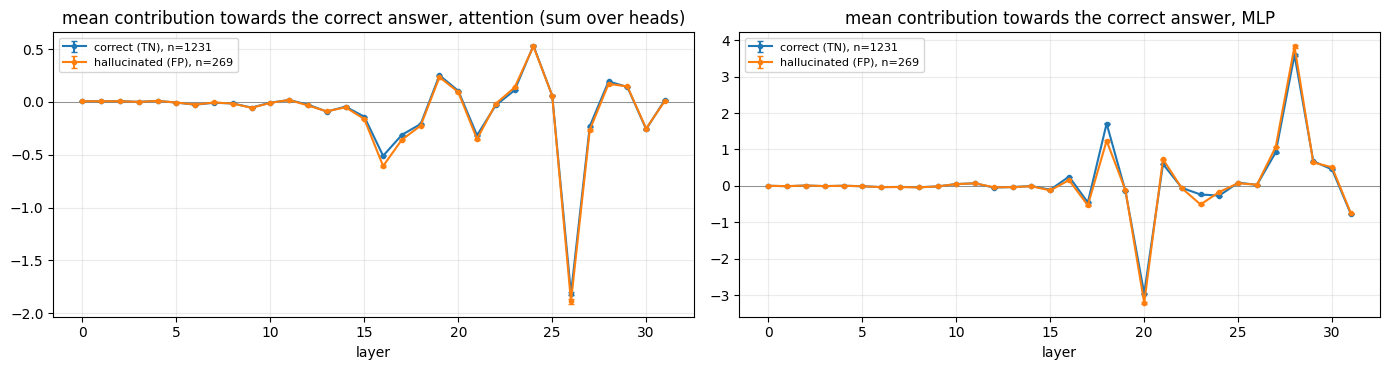

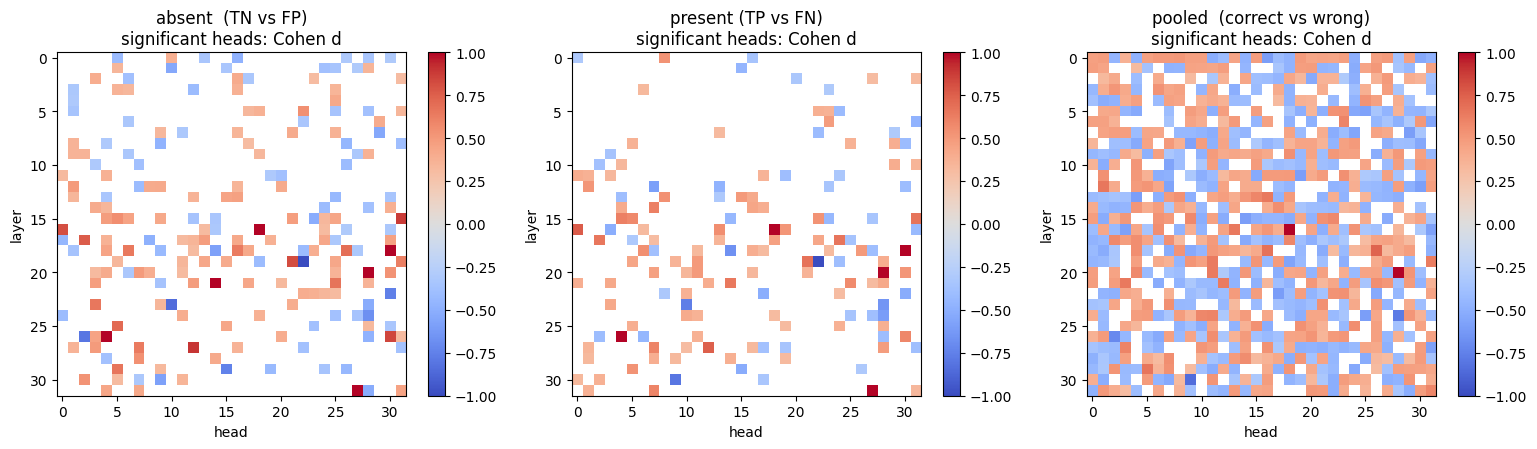

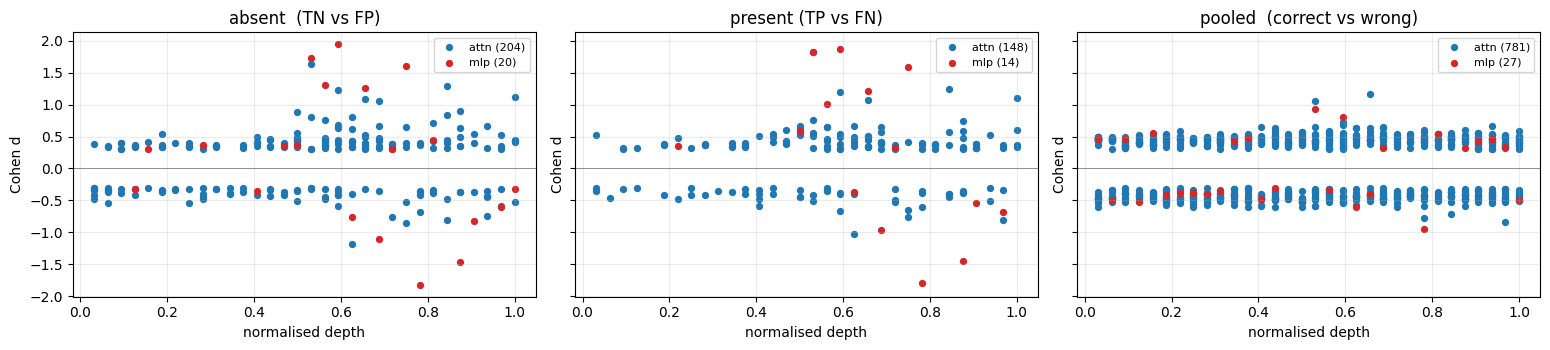

In [5]:
# 5. STEP 1 PLOTS: per-layer means with 95% CI, head heatmaps of Cohen d, depth profile of significant components
def ci(a): return 1.96 * a.std(0, ddof=1) / np.sqrt(len(a))
def layer_sums(X, n): return X[:, 1:1 + N_LAYER * N_HEAD].reshape(len(X), N_LAYER, N_HEAD).sum(-1), X[:, 1 + N_LAYER * N_HEAD:]

name = "absent  (TN vs FP)"
if name in R_o:
    _, good, bad = R_o[name]
    A, M = layer_sums(X_o, len(X_o))
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
    for a_, S, t in zip(ax, [A, M], ["attention (sum over heads)", "MLP"]):
        for msk, lab in [(good, "correct (TN)"), (bad, "hallucinated (FP)")]:
            a_.errorbar(np.arange(N_LAYER), S[msk].mean(0), yerr=ci(S[msk]), marker="o", ms=3, capsize=2, label=f"{lab}, n={msk.sum()}")
        a_.axhline(0, color="gray", lw=0.6); a_.set_title(f"mean contribution towards the correct answer, {t}"); a_.set_xlabel("layer"); a_.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/ours_layers_absent.png"); plt.show()

fig, axs = plt.subplots(1, len(R_o), figsize=(5.2 * len(R_o), 4.6), squeeze=False)
for a_, (nm, (res, _, _)) in zip(axs[0], R_o.items()):
    h = res[res.kind == "attn"]; dmat = h.d.values.reshape(N_LAYER, N_HEAD); smat = h.sig.values.reshape(N_LAYER, N_HEAD)
    im = a_.imshow(np.where(smat, dmat, np.nan), cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    a_.set_title(f"{nm}\nsignificant heads: Cohen d"); a_.set_xlabel("head"); a_.set_ylabel("layer"); a_.grid(False); plt.colorbar(im, ax=a_)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/ours_head_heatmaps.png"); plt.show()

fig, axs = plt.subplots(1, len(R_o), figsize=(5.2 * len(R_o), 3.6), squeeze=False, sharey=True)
for a_, (nm, (res, _, _)) in zip(axs[0], R_o.items()):
    s = res[res.sig]
    for kd, c in [("attn", "tab:blue"), ("mlp", "tab:red")]:
        q = s[s.kind == kd]; a_.scatter(q.depth, q.d, s=18, c=c, label=f"{kd} ({len(q)})")
    a_.axhline(0, color="gray", lw=0.6); a_.set_title(nm); a_.set_xlabel("normalised depth"); a_.set_ylabel("Cohen d"); a_.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/ours_depth_profile.png"); plt.show()

In [6]:
# 6. STEP 1: HELD-OUT POLARITY CHECK + candidates for the ablation notebook
pooled = "pooled  (correct vs wrong)"
if pooled in R_o:
    res, good, bad = R_o[pooled]
    # split by IMAGE id parity (question-number parity is confounded with the ground truth: even numbers = all "yes" questions)
    disc = np.array([int(re.findall(r"\d+", str(i))[-1]) % 2 == 0 for i in O["image_id"]]); ev = ~disc
    print(f"discovery half (even image ids): {disc.sum()} questions, ground truth {dict(Counter(O['gt'][disc]))} | evaluation half: {ev.sum()}, {dict(Counter(O['gt'][ev]))}")
    assert len(set(O["gt"][disc])) == 2 and len(set(O["gt"][ev])) == 2, "split is confounded with the ground truth"
    res_d, (nd_a, nd_b) = welch(X_o, good & disc, bad & disc)
    s_d = res_d[res_d.sig]; full_set = set(res.name[res.sig])
    print(f"discovery half: {nd_a} correct vs {nd_b} wrong | significant {len(s_d)} ({(s_d.d > 0).sum()} grounding, {(s_d.d < 0).sum()} hallucination) | also significant in the full-sample test: {len(set(s_d.name) & full_set)}")

    # polarity check: sets are chosen on the discovery half and summed on BOTH halves. Only the held-out half is a fair test;
    # random sets of the same size show what a set of that size does anyway (any large set tracks the total, which decides correct vs wrong)
    rng = np.random.default_rng(0)
    print("\nsummed contribution of the selected set, signed towards the correct answer:")
    for pw in ["grounding", "hallucination"]:
        sel = np.flatnonzero((res_d.pathway == pw).values)
        if len(sel) == 0: print(pw, ": none"); continue
        s_all = X_o[:, sel].sum(1)
        rnd = np.array([(lambda v: v[good & ev].mean() - v[bad & ev].mean())(X_o[:, rng.choice(X_o.shape[1], len(sel), replace=False)].sum(1)) for _ in range(200)])
        dif = s_all[good & ev].mean() - s_all[bad & ev].mean()
        print(f"  {pw:14s} n={len(sel):3d} | discovery half (selected here, circular): correct {s_all[good & disc].mean():+.3f}, wrong {s_all[bad & disc].mean():+.3f}"
              f" | HELD-OUT: correct {s_all[good & ev].mean():+.3f}, wrong {s_all[bad & ev].mean():+.3f}, difference {dif:+.3f}"
              f" | random same-size sets, held-out difference {rnd.mean():+.3f} +- {rnd.std():.3f} (z of the selected set: {(dif - rnd.mean()) / max(rnd.std(), 1e-9):+.1f})")

    # candidates for the ablation notebook: ranked by the size of the effect IN LOGITS, not by Cohen d
    cand = s_d.assign(gap=s_d.mean_correct - s_d.mean_wrong).assign(abs_gap=lambda t: t.gap.abs()).sort_values("abs_gap", ascending=False)
    print("\ntop candidates by |gap| (logits):", ", ".join(f"{r['name']}({r['gap']:+.3f})" for _, r in cand.head(10).iterrows()))
    out = [dict(name=r["name"], kind=r["kind"], layer=int(r["layer"]), head=int(r["head"]), d=float(r["d"]), gap=float(r["gap"]), pathway=r["pathway"]) for _, r in cand.head(40).iterrows()]
    json.dump(out, open(f"{OUT_DIR}/candidates.json", "w"), indent=1)
    print("saved", f"{OUT_DIR}/candidates.json", f"({len(out)} components from the discovery half)")

discovery half (even image ids): 1410 questions, ground truth {np.str_('yes'): 705, np.str_('no'): 705} | evaluation half: 1590, {np.str_('yes'): 795, np.str_('no'): 795}
discovery half: 1027 correct vs 383 wrong | significant 789 (414 grounding, 375 hallucination) | also significant in the full-sample test: 774

summed contribution of the selected set, signed towards the correct answer:
  grounding      n=414 | discovery half (selected here, circular): correct +1.829, wrong -4.566 | HELD-OUT: correct +1.948, wrong -4.888, difference +6.836 | random same-size sets, held-out difference +0.195 +- 1.166 (z of the selected set: +5.7)
  hallucination  n=375 | discovery half (selected here, circular): correct -1.381, wrong +4.140 | HELD-OUT: correct -1.491, wrong +4.437, difference -5.928 | random same-size sets, held-out difference +0.234 +- 1.315 (z of the selected set: -4.7)

top candidates by |gap| (logits): L28.mlp(+1.495), L20.mlp(-1.152), L18.mlp(+1.082), L26H3(-0.654), L31.mlp(-0.360

## Step 1b: does averaging hide per-question structure?

Group means only show the *average* push. A component can have a mean gap near 0 and still vary a lot from question to question (positive on some images, negative on others). Two exact checks:

* **Variance test**: Levene (median-centred) per component, TN vs FP, BH-corrected. "Variance-only" components (variance differs, mean does not) are the candidates for averaged-out signals.
* **Variance share**: within a group, the per-question logit difference is the sum of the components, so `Var(sum) = sum_c Cov(x_c, sum)`. The share `Cov(x_c, sum)/Var(sum)` adds up to exactly 1 and says which components drive the *spread* of the answers, as opposed to the *mean gap* in the table above.

Caveat: large per-image variation alone is not evidence of hallucination, since it can simply be the model reading image content correctly. The corrupted-image control (step 3) shows whether the variation comes from the image.

TN n=1231, FP n=269 | mean-significant 224 | variance-significant 53 | variance-only (hidden from the mean test) 36 | both 17
variance-only components, largest variance ratio:
  name  gap_TN_minus_FP  sd_TN  sd_FP  log2_var_ratio_FP_over_TN   padj
L24H16           0.0005 0.0038 0.0021                    -1.6777 0.0007
L26H25           0.0006 0.0067 0.0049                    -0.9126 0.0014
 L25H0          -0.0004 0.0054 0.0072                     0.8512 0.0022
L31H16          -0.0009 0.0079 0.0059                    -0.8312 0.0110
L29H31          -0.0018 0.0071 0.0054                    -0.7963 0.0066
L10H27          -0.0002 0.0041 0.0032                    -0.7432 0.0004
L26H14           0.0012 0.0082 0.0064                    -0.7296 0.0005
L20H10          -0.0004 0.0068 0.0087                     0.7113 0.0004
L19H20           0.0016 0.0063 0.0049                    -0.7095 0.0003
 L13H8          -0.0005 0.0040 0.0051                     0.7007 0.0013
L25H11          -0.0002 0.0045 0

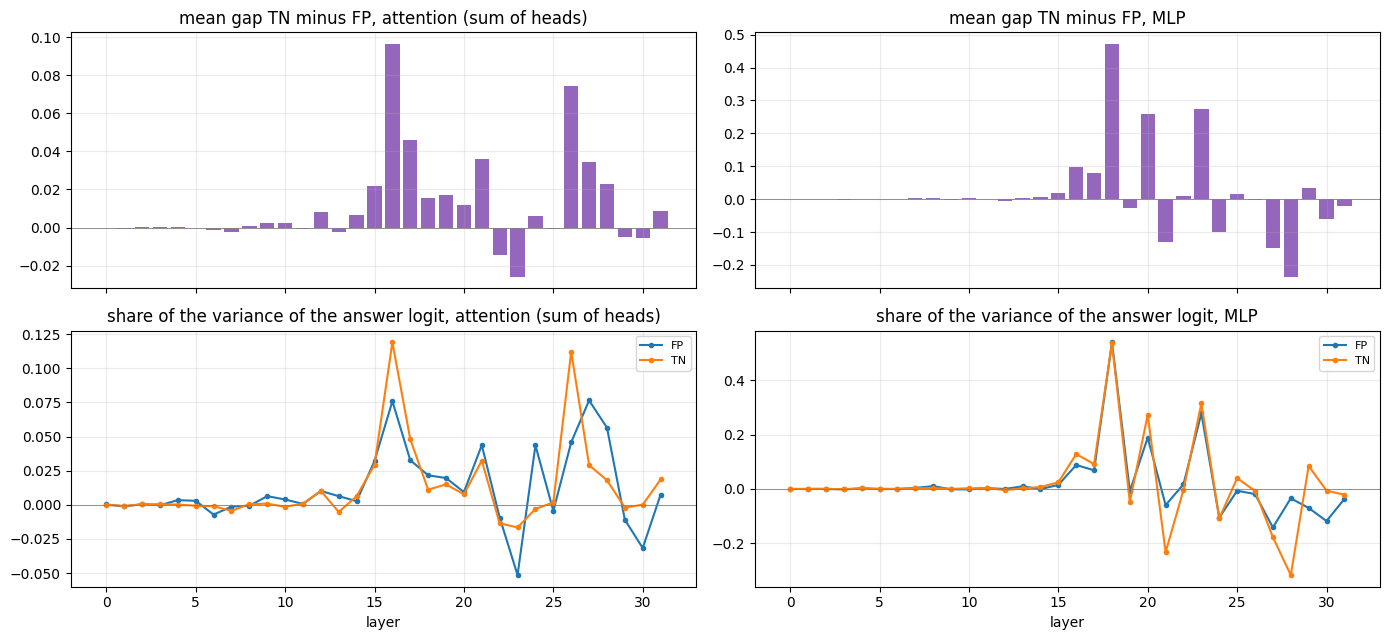

In [7]:
# 6b. STEP 1b: VARIANCE TEST AND VARIANCE SHARE (object absent: TN vs FP)
nm_abs = "absent  (TN vs FP)"
if nm_abs in R_o:
    res_m, good, bad = R_o[nm_abs]
    Xg, Xb = X_o[good], X_o[bad]
    ok = (Xg.std(0) > 0) & (Xb.std(0) > 0)
    lev_p = np.array([stats.levene(Xg[:, j], Xb[:, j], center="median").pvalue if ok[j] else 1.0 for j in range(X_o.shape[1])])
    V = pd.DataFrame(dict(name=NAMES, kind=KIND, layer=LAYER, gap_TN_minus_FP=Xg.mean(0) - Xb.mean(0), d=res_m.d.values,
                          sd_TN=Xg.std(0, ddof=1), sd_FP=Xb.std(0, ddof=1),
                          log2_var_ratio_FP_over_TN=np.log2((Xb.var(0, ddof=1) + 1e-12) / (Xg.var(0, ddof=1) + 1e-12)), p=lev_p))
    V["padj"] = bh(V.p.values)
    V["var_sig"] = (V.padj < ALPHA) & (V.log2_var_ratio_FP_over_TN.abs() > 0.5)
    V["mean_sig"] = res_m.sig.values
    print(f"TN n={good.sum()}, FP n={bad.sum()} | mean-significant {int(V.mean_sig.sum())} | variance-significant {int(V.var_sig.sum())} | "
          f"variance-only (hidden from the mean test) {int((V.var_sig & ~V.mean_sig).sum())} | both {int((V.var_sig & V.mean_sig).sum())}")
    vo = V[V.var_sig & ~V.mean_sig]
    if len(vo):
        print("variance-only components, largest variance ratio:")
        print(vo.reindex(vo.log2_var_ratio_FP_over_TN.abs().sort_values(ascending=False).index).head(TOPK)[["name", "gap_TN_minus_FP", "sd_TN", "sd_FP", "log2_var_ratio_FP_over_TN", "padj"]].round(4).to_string(index=False))

    # variance share: Cov(x_c, sum) / Var(sum), adds up to 1 in each group
    def var_share(X):
        s = X.sum(1); return ((X - X.mean(0)) * (s - s.mean())[:, None]).sum(0) / (len(X) - 1) / s.var(ddof=1)
    V["share_TN"], V["share_FP"] = var_share(Xg), var_share(Xb)
    V.to_csv(f"{OUT_DIR}/step1b_variance.csv", index=False)
    print(f"\nmean total (signed) logit diff: TN {Xg.sum(1).mean():+.3f}, FP {Xb.sum(1).mean():+.3f} | gap {V.gap_TN_minus_FP.sum():+.3f} | sd of total: TN {Xg.sum(1).std():.3f}, FP {Xb.sum(1).std():.3f}")
    print(f"top-10 components by variance share: TN {np.sort(V.share_TN.values)[::-1][:10].sum():.2f}, FP {np.sort(V.share_FP.values)[::-1][:10].sum():.2f} (of 1.00)")
    print("\ncomponents driving the SPREAD of FP answers vs their MEAN gap:")
    t = V.reindex(V.share_FP.abs().sort_values(ascending=False).index).head(TOPK)
    t = t.assign(gap_rank=V.gap_TN_minus_FP.abs().rank(ascending=False).reindex(t.index).astype(int))
    print(t[["name", "share_FP", "share_TN", "gap_TN_minus_FP", "gap_rank", "sd_FP", "sd_TN"]].round(3).to_string(index=False))

    def lay(v):  # layer sums of an additive per-component vector
        return v[1:1 + N_LAYER * N_HEAD].reshape(N_LAYER, N_HEAD).sum(1), v[1 + N_LAYER * N_HEAD:]
    fig, ax = plt.subplots(2, 2, figsize=(14, 6.5), sharex=True)
    for col, (nm, a_idx) in enumerate([("attention (sum of heads)", 0), ("MLP", 1)]):
        g = lay(V.gap_TN_minus_FP.values)[a_idx]; sf = lay(V.share_FP.values)[a_idx]; st = lay(V.share_TN.values)[a_idx]
        ax[0, col].bar(np.arange(N_LAYER), g, color="tab:purple"); ax[0, col].set_title(f"mean gap TN minus FP, {nm}")
        ax[1, col].plot(np.arange(N_LAYER), sf, "o-", ms=3, label="FP"); ax[1, col].plot(np.arange(N_LAYER), st, "o-", ms=3, label="TN")
        ax[1, col].set_title(f"share of the variance of the answer logit, {nm}"); ax[1, col].set_xlabel("layer"); ax[1, col].legend(fontsize=8)
        for r in (0, 1): ax[r, col].axhline(0, c="gray", lw=0.6)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/step1b_variance.png"); plt.show()

## Step 1c: fixed-answer contrasts (does any component track the TRUTH, not just the model's own answer?)

TN vs FP and TP vs FN compare groups that also differ in the model's answer, so the biggest components can simply be the ones that carry the answer. Here the **answer is held fixed** and only the ground truth varies:

* answered **yes**: TP (object present) vs FP (absent); answered **no**: FN (present) vs TN (absent). Gap = present minus absent, raw contribution to Yes-No (positive = pushes towards yes more when the object is really there).
* **Margin-matched**: groups are compared within bins of the model's own Yes-No logit difference (8 quantile bins, per-bin Welch statistics combined with weights sqrt(na*nb/(na+nb)), Stouffer z, BH), so margin differences cannot explain a result. After matching, the total gap is about 0 by construction; what remains is *which* components move.
* Components with the **same sign in both** contrasts and significant in both are truth-tracking independently of the answer.
* The 2x2 table gives, for the top components, raw group means for TP / FP / TN / FN and the unweighted *answer effect* ((TP+FP)/2 - (TN+FN)/2) and *truth effect* ((TP+FN)/2 - (TN+FP)/2). A component with answer effect >> truth effect carries the decision, not the evidence.

In [8]:
# 6c. STEP 1c: FIXED-ANSWER CONTRASTS
Xr, oc, ldv = comp_matrix(O, signed=False), O["outcome"], O["ld"]
def matched(a_, b_, nbins=8, min_n=5):
    sel = (oc == a_) | (oc == b_)
    edges = np.quantile(ldv[sel], np.linspace(0, 1, nbins + 1)[1:-1]); bins = np.digitize(ldv, edges)
    G, D, Z = np.zeros(Xr.shape[1]), np.zeros(Xr.shape[1]), np.zeros(Xr.shape[1]); W = W2 = 0.0; used = 0
    for k in range(nbins):
        ma, mb = sel & (bins == k) & (oc == a_), sel & (bins == k) & (oc == b_)
        if ma.sum() < min_n or mb.sum() < min_n: continue
        r, _ = welch(Xr, ma, mb); w = math.sqrt(ma.sum() * mb.sum() / (ma.sum() + mb.sum()))
        G += w * r.gap.values; D += w * r.d.values; Z += w * r.t.values; W += w; W2 += w * w; used += 1
    if used == 0: return None, 0
    z = Z / math.sqrt(W2); padj = bh(2 * stats.norm.sf(np.abs(z)))
    return pd.DataFrame(dict(name=NAMES, kind=KIND, layer=LAYER, gap=G / W, d=D / W, z=z, padj=padj, sig=(padj < ALPHA) & (np.abs(D / W) > D_MIN))), used

FX = {}
for label, a_, b_ in [("answered YES: present (TP) minus absent (FP)", "TP", "FP"), ("answered NO: present (FN) minus absent (TN)", "FN", "TN")]:
    if (oc == a_).sum() < 10 or (oc == b_).sum() < 10: print(label, ": too few samples"); continue
    raw, _ = welch(Xr, oc == a_, oc == b_)
    mt, used = matched(a_, b_)
    FX[label] = (raw, mt)
    print(f"\n=== {label} | n={int((oc == a_).sum())} vs {int((oc == b_).sum())} | mean logit diff {ldv[oc == a_].mean():+.3f} vs {ldv[oc == b_].mean():+.3f}")
    print(f"unmatched: total gap {raw.gap.sum():+.3f} | significant {int(raw.sig.sum())}")
    print(raw.reindex(raw.gap.abs().sort_values(ascending=False).index).head(TOPK)[["name", "gap", "d", "padj"]].round(4).to_string(index=False))
    if mt is not None:
        print(f"margin-matched ({used} bins): total gap {mt.gap.sum():+.3f} | significant {int(mt.sig.sum())}")
        print(mt.reindex(mt.gap.abs().sort_values(ascending=False).index).head(TOPK)[["name", "gap", "d", "padj", "sig"]].round(4).to_string(index=False))

if len(FX) == 2:
    (la, (ra, ma_)), (lb, (rb, mb_)) = list(FX.items())
    print("\n=== truth-tracking independent of the answer: same sign and significant in both contrasts")
    for tag, A_, B_ in [("unmatched", ra, rb), ("margin-matched", ma_, mb_)]:
        if A_ is None or B_ is None: continue
        both = A_.sig.values & B_.sig.values & (np.sign(A_.gap.values) == np.sign(B_.gap.values))
        print(f"{tag}: gap correlation between the two contrasts {np.corrcoef(A_.gap, B_.gap)[0, 1]:+.3f} (Spearman {stats.spearmanr(A_.gap, B_.gap)[0]:+.3f}) | components significant with the same sign in both: {int(both.sum())}")
        if both.sum():
            t = pd.DataFrame(dict(name=np.array(NAMES)[both], gap_yes=A_.gap.values[both], gap_no=B_.gap.values[both]))
            print(t.reindex((t.gap_yes.abs() + t.gap_no.abs()).sort_values(ascending=False).index).head(TOPK).round(4).to_string(index=False))

M = {g: Xr[oc == g].mean(0) for g in ["TP", "FP", "TN", "FN"] if (oc == g).sum()}
if len(M) == 4:
    ans_eff = (M["TP"] + M["FP"]) / 2 - (M["TN"] + M["FN"]) / 2          # model answered yes minus answered no
    tru_eff = (M["TP"] + M["FN"]) / 2 - (M["TN"] + M["FP"]) / 2          # object present minus absent
    T = pd.DataFrame(dict(name=NAMES, kind=KIND, TP=M["TP"], FP=M["FP"], TN=M["TN"], FN=M["FN"], answer_effect=ans_eff, truth_effect=tru_eff))
    T.to_csv(f"{OUT_DIR}/step1c_answer_vs_truth.csv", index=False)
    print("\n=== 2x2 table: raw mean contribution to Yes-No (positive = towards yes), top components by |answer effect| + |truth effect|")
    print(T.reindex((T.answer_effect.abs() + T.truth_effect.abs()).sort_values(ascending=False).index).head(15)[["name", "TP", "FP", "TN", "FN", "answer_effect", "truth_effect"]].round(3).to_string(index=False))
    print(f"sum over all components: answer effect {ans_eff.sum():+.3f} | truth effect {tru_eff.sum():+.3f}  (group mean logit diff: TP {ldv[oc == 'TP'].mean():+.3f}, FP {ldv[oc == 'FP'].mean():+.3f}, TN {ldv[oc == 'TN'].mean():+.3f}, FN {ldv[oc == 'FN'].mean():+.3f})")
    for k_ in ["attn", "mlp"]:
        m_ = (KIND == k_); print(f"  {k_}: answer effect {ans_eff[m_].sum():+.3f}, truth effect {tru_eff[m_].sum():+.3f}")


=== answered YES: present (TP) minus absent (FP) | n=954 vs 269 | mean logit diff +0.528 vs +0.265
unmatched: total gap +0.263 | significant 115
   name     gap       d   padj
L18.mlp  0.1857  0.7325 0.0000
L23.mlp  0.0984  0.5928 0.0000
L20.mlp  0.0833  0.4116 0.0000
L27.mlp -0.0803 -0.7615 0.0000
L29.mlp -0.0428 -0.3206 0.0001
L24.mlp -0.0386 -0.7048 0.0000
L16.mlp  0.0344  0.7168 0.0000
L28.mlp  0.0301  0.1234 0.1578
 L19H10  0.0249  0.1921 0.0255
L21.mlp -0.0224 -0.3051 0.0002
  L16H0  0.0222  0.3615 0.0000
 L26H27  0.0206  0.2742 0.0034
margin-matched (8 bins): total gap +0.016 | significant 107
   name     gap       d   padj   sig
L28.mlp  0.0436  0.1667 0.0134 False
L18.mlp  0.0402  0.2779 0.0091 False
L27.mlp -0.0359 -0.4328 0.0000  True
L30.mlp  0.0295  0.3955 0.0000  True
 L19H10  0.0290  0.2244 0.0172 False
  L26H3 -0.0221 -0.1694 0.0219 False
L20.mlp  0.0213  0.1213 0.2915 False
L23.mlp  0.0195  0.1770 0.3170 False
 L26H27  0.0163  0.2321 0.1810 False
L15.mlp  0.0135  0.29

In [9]:
# 7. STEP 5: HIGH-MARGIN SUBSET (confident answers only)
thr = np.quantile(np.abs(O["ld"]), MARGIN_Q)
mask_hi = np.abs(O["ld"]) >= thr
print(f"keeping |logit diff| >= {thr:.3f}: {mask_hi.sum()} of {len(mask_hi)} samples | outcomes {dict(Counter(O['outcome'][mask_hi]))}")
print("NOTE: this subset is selected on |logit diff|, the quantity that defines correct/wrong, so d is inflated mechanically; use it as a robustness view only. The margin-matched fixed-answer contrast (step 1c) is the controlled version.")
X_hi, R_hi = run_contrasts(O, "ours_highmargin", mask=mask_hi)
# overlap of significant sets between full and high-margin analyses
for nm in R_hi:
    a = set(R_o[nm][0].name[R_o[nm][0].sig]); b = set(R_hi[nm][0].name[R_hi[nm][0].sig])
    print(f"{nm}: significant in full {len(a)}, in high-margin {len(b)}, in both {len(a & b)}")

keeping |logit diff| >= 0.453: 1504 of 3000 samples | outcomes {np.str_('TP'): 493, np.str_('TN'): 797, np.str_('FN'): 158, np.str_('FP'): 56}
NOTE: this subset is selected on |logit diff|, the quantity that defines correct/wrong, so d is inflated mechanically; use it as a robustness view only. The margin-matched fixed-answer contrast (step 1c) is the controlled version.
[ours_highmargin] absent  (TN vs FP): n_correct=797, n_wrong=56 | significant: 458 (grounding d>0: 242, hallucination d<0: 216; heads 434, MLPs 24)
  largest components by |gap| in logits (gap = mean_correct - mean_wrong); the top-12 carry +1.033 of the total gap +1.470. Significant counts are inflated because correct/wrong is defined by the sum of the components.
   name  mean_correct  mean_wrong     gap       d  padj       pathway
L18.mlp        1.8271      1.0493  0.7778  3.5659   0.0     grounding
L23.mlp       -0.1687     -0.6011  0.4324  2.7785   0.0     grounding
L20.mlp       -2.8883     -3.2737  0.3854  2.0523

questions: 3000
accuracy  ours 0.728 | LLaVA 0.894
yes-rate  ours 0.408 | LLaVA 0.523
logit diff: Pearson +0.593 | Spearman +0.611
answer agreement (same yes/no): 0.721
            LLaVA right  LLaVA wrong
                                    
ours right         2014          171
ours wrong          667          148
discordant: LLaVA-only-right 667, ours-only-right 171 | McNemar exact p = 6.98e-70
outcome tables (rows ours, cols LLaVA):
col_0  FN   FP    TN   TP
row_0                    
FN     64    0     0  482
FP      0   84   185    0
TN      0  110  1121    0
TP     61    0     0  893


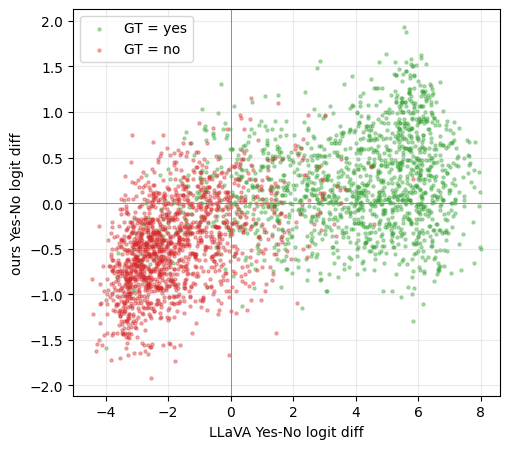

In [10]:
# 8. STEP 2: PAIRED COMPARISON WITH LLaVA-1.5 (same question ids)
assert L is not None, "attach the dla-llava dataset as input"
print(f"questions: {len(O['qid'])}")
print(f"accuracy  ours {O['correct'].mean():.3f} | LLaVA {L['correct'].mean():.3f}")
print(f"yes-rate  ours {(O['pred'] == 'yes').mean():.3f} | LLaVA {(L['pred'] == 'yes').mean():.3f}")
print(f"logit diff: Pearson {np.corrcoef(O['ld'], L['ld'])[0, 1]:+.3f} | Spearman {stats.spearmanr(O['ld'], L['ld'])[0]:+.3f}")
print(f"answer agreement (same yes/no): {(O['pred'] == L['pred']).mean():.3f}")

tab = pd.crosstab(pd.Series(np.where(O["correct"], "ours right", "ours wrong"), name=""), pd.Series(np.where(L["correct"], "LLaVA right", "LLaVA wrong"), name=""))
print(tab)
b, c = int(((~O["correct"]) & L["correct"]).sum()), int((O["correct"] & (~L["correct"])).sum())
print(f"discordant: LLaVA-only-right {b}, ours-only-right {c} | McNemar exact p = {stats.binomtest(b, b + c, 0.5).pvalue:.3g}")
print("outcome tables (rows ours, cols LLaVA):"); print(pd.crosstab(O["outcome"], L["outcome"]))

fig, ax = plt.subplots(1, 1, figsize=(5.2, 4.6))
for gtv, col in [("yes", "tab:green"), ("no", "tab:red")]:
    m = O["gt"] == gtv; ax.scatter(L["ld"][m], O["ld"][m], s=5, alpha=0.35, c=col, label=f"GT = {gtv}")
ax.axhline(0, c="gray", lw=0.6); ax.axvline(0, c="gray", lw=0.6); ax.set_xlabel("LLaVA Yes-No logit diff"); ax.set_ylabel("ours Yes-No logit diff"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/paired_logit_diffs.png"); plt.show()

mean logit diff: LLaVA +1.055, ours -0.127, gap +1.182 | sum of component gaps +1.182
embed gap +0.003 | all attention +0.115 | all MLP +1.064


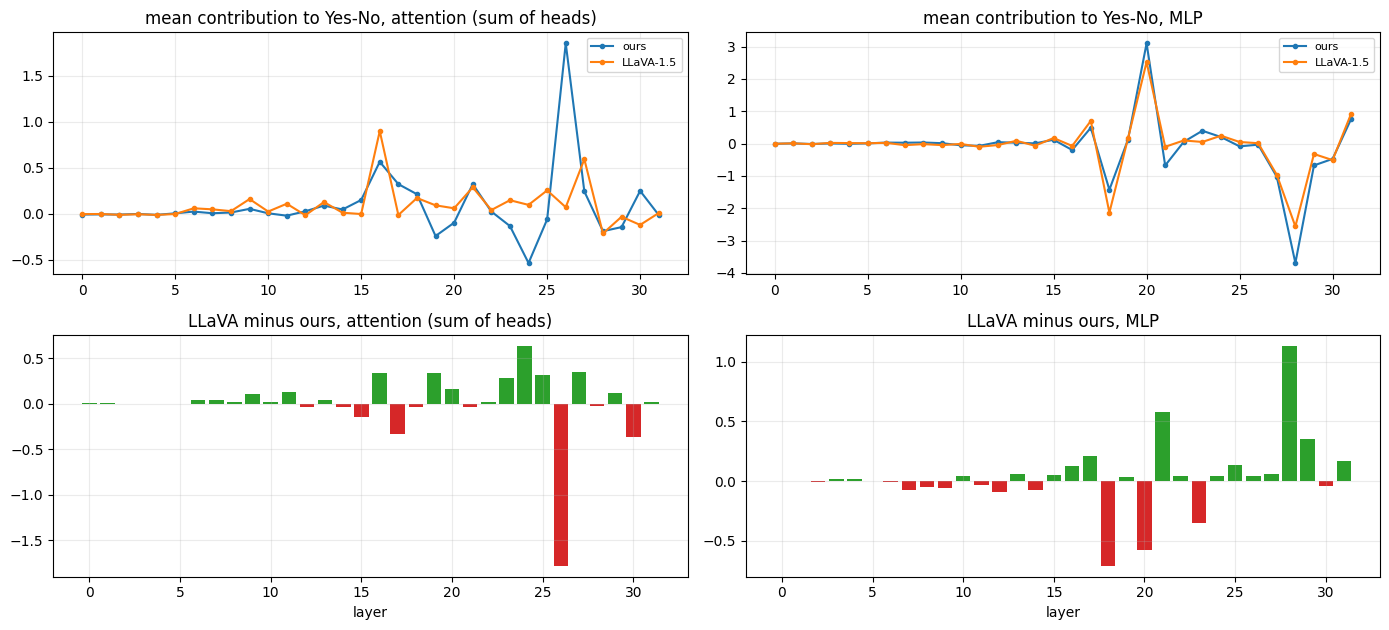

largest components of the gap (LLaVA minus ours):
   name kind   ours  llava    gap
  L26H3 attn  1.535  0.004 -1.531
L28.mlp  mlp -3.692 -2.560  1.132
L18.mlp  mlp -1.425 -2.133 -0.708
L20.mlp  mlp  3.103  2.524 -0.579
L21.mlp  mlp -0.675 -0.098  0.578
 L17H16 attn  0.588  0.032 -0.556
  L24H8 attn -0.555 -0.031  0.523
 L19H10 attn -0.492  0.004  0.495
 L26H27 attn  0.426  0.027 -0.399
L29.mlp  mlp -0.674 -0.320  0.353
L23.mlp  mlp  0.398  0.052 -0.346
  L27H7 attn  0.135  0.470  0.335
 L23H10 attn -0.172  0.131  0.303
 L19H21 attn  0.245  0.006 -0.239
L17.mlp  mlp  0.491  0.702  0.211
  L30H7 attn  0.219  0.009 -0.210
 L21H30 attn  0.213  0.010 -0.203
L31.mlp  mlp  0.763  0.929  0.166
 L21H14 attn  0.059  0.224  0.166
 L17H11 attn -0.161  0.001  0.162


In [11]:
# 9. STEP 2: WHERE DOES THE NET-BIAS GAP COME FROM?  mean(LLaVA) - mean(ours) per component; sums exactly to the logit-diff gap
Xo_raw, Xl_raw = comp_matrix(O, signed=False), comp_matrix(L, signed=False)
gap = Xl_raw.mean(0) - Xo_raw.mean(0)
print(f"mean logit diff: LLaVA {L['ld'].mean():+.3f}, ours {O['ld'].mean():+.3f}, gap {L['ld'].mean() - O['ld'].mean():+.3f} | sum of component gaps {gap.sum():+.3f}")

def lay(v):  # layer sums of a per-component vector
    return v[1:1 + N_LAYER * N_HEAD].reshape(N_LAYER, N_HEAD).sum(-1), v[1 + N_LAYER * N_HEAD:]
ga, gm = lay(gap); mo_a, mo_m = lay(Xo_raw.mean(0)); ml_a, ml_m = lay(Xl_raw.mean(0))
print(f"embed gap {gap[0]:+.3f} | all attention {ga.sum():+.3f} | all MLP {gm.sum():+.3f}")
fig, ax = plt.subplots(2, 2, figsize=(14, 6.4))
for j, (so, sl, sg, t) in enumerate([(mo_a, ml_a, ga, "attention (sum of heads)"), (mo_m, ml_m, gm, "MLP")]):
    ax[0, j].plot(so, marker="o", ms=3, label="ours"); ax[0, j].plot(sl, marker="o", ms=3, label="LLaVA-1.5"); ax[0, j].set_title(f"mean contribution to Yes-No, {t}"); ax[0, j].legend(fontsize=8)
    ax[1, j].bar(np.arange(N_LAYER), sg, color=np.where(sg > 0, "tab:green", "tab:red")); ax[1, j].set_title(f"LLaVA minus ours, {t}"); ax[1, j].set_xlabel("layer")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/paired_gap_by_layer.png"); plt.show()

gdf = pd.DataFrame(dict(name=NAMES, kind=KIND, ours=Xo_raw.mean(0), llava=Xl_raw.mean(0), gap=gap))
print("largest components of the gap (LLaVA minus ours):")
print(gdf.reindex(gdf.gap.abs().sort_values(ascending=False).index).head(TOPK + 8).round(3).to_string(index=False))
gdf.to_csv(f"{OUT_DIR}/paired_gap_components.csv", index=False)

MLP layers, correlation of per-question contribution (ours vs LLaVA):
   name  corr
L18.mlp 0.601
L24.mlp 0.587
L16.mlp 0.559
L27.mlp 0.558
L21.mlp 0.522
L23.mlp 0.463
L20.mlp 0.446
L17.mlp 0.367
heads: median corr +0.089 | fraction with corr > 0.3: 0.099
most correlated heads:
  name  corr
L22H16 0.823
 L24H3 0.807
L22H27 0.790
 L22H9 0.775
 L21H1 0.756
L23H20 0.745
L23H31 0.719
L24H15 0.711


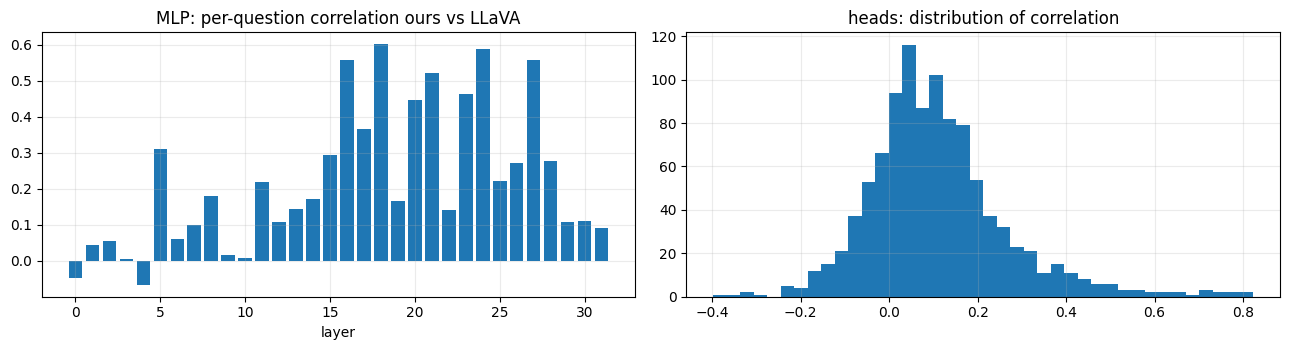

In [12]:
# 10. STEP 2: PER-COMPONENT CORRELATION ACROSS THE SAME QUESTIONS
def colcorr(A, B):
    A = A - A.mean(0); B = B - B.mean(0); sa, sb = A.std(0), B.std(0); ok = (sa > 0) & (sb > 0)
    return np.where(ok, (A * B).mean(0) / np.where(ok, sa * sb, 1), np.nan)
cc = colcorr(Xo_raw, Xl_raw)
cdf = pd.DataFrame(dict(name=NAMES, kind=KIND, layer=LAYER, corr=cc)); cdf.to_csv(f"{OUT_DIR}/paired_component_corr.csv", index=False)
mm = cdf[cdf.kind == "mlp"]; print("MLP layers, correlation of per-question contribution (ours vs LLaVA):")
print(mm.sort_values("corr", ascending=False).head(8)[["name", "corr"]].round(3).to_string(index=False))
hh = cdf[cdf.kind == "attn"].dropna()
print(f"heads: median corr {hh['corr'].median():+.3f} | fraction with corr > 0.3: {(hh['corr'] > 0.3).mean():.3f}")
print("most correlated heads:"); print(hh.sort_values("corr", ascending=False).head(8)[["name", "corr"]].round(3).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(mm.layer, mm["corr"]); ax[0].set_title("MLP: per-question correlation ours vs LLaVA"); ax[0].set_xlabel("layer")
ax[1].hist(hh["corr"], bins=40); ax[1].set_title("heads: distribution of correlation"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/paired_corr.png"); plt.show()

In [13]:
# 11. STEP 2: QUESTIONS WHERE ONE MODEL IS RIGHT AND THE OTHER WRONG
Xo_s, Xl_s = comp_matrix(O), comp_matrix(L)          # signed: positive = towards the correct answer
def show_examples(mask, title, k=12):
    ids = np.where(mask)[0][:k]; print(f"\n{title}: {mask.sum()} questions")
    for i in ids:
        print(f"  {O['qid'][i]:12s} GT={O['gt'][i]:3s} ours ld {O['ld'][i]:+.2f} | LLaVA ld {L['ld'][i]:+.2f} | {QTEXT.get(O['qid'][i], '')}")
    return ids

def paired_components(mask, title):
    diff = (Xl_s - Xo_s)[mask]; n = len(diff)
    if n < 10: print(f"{title}: too few ({n})"); return None
    m, s = diff.mean(0), diff.std(0, ddof=1); ok = s > 0
    t = np.where(ok, m / np.where(ok, s / np.sqrt(n), 1), 0.0); p = np.where(ok, 2 * stats.t.sf(np.abs(t), n - 1), 1.0)
    df = pd.DataFrame(dict(name=NAMES, kind=KIND, mean_diff=m, dz=np.where(ok, m / np.where(ok, s, 1), 0.0), p=p, padj=bh(p)))
    df["sig"] = (df.padj < ALPHA) & (df.dz.abs() > D_MIN)
    print(f"{title}: n={n} | mean total shift towards the correct answer (LLaVA minus ours) {diff.sum(1).mean():+.3f} | significant components {df.sig.sum()}")
    print("  positive = LLaVA's component pushes towards the correct answer more than ours")
    print(df.reindex(df.mean_diff.abs().sort_values(ascending=False).index).head(TOPK)[["name", "mean_diff", "dz", "padj", "sig"]].round(4).to_string(index=False))
    return df

m_a = (~O["correct"]) & L["correct"]; m_b = O["correct"] & (~L["correct"])
show_examples(m_a & (O["gt"] == "no"), "ours HALLUCINATES (says yes, absent object), LLaVA correct")
show_examples(m_b & (L["gt"] == "no"), "LLaVA HALLUCINATES, ours correct")
Pa = paired_components(m_a, "ours wrong / LLaVA right")
Pb = paired_components(m_b, "ours right / LLaVA wrong")
Pc = paired_components(m_a & (O["gt"] == "no"), "ours hallucinates / LLaVA correct (absent objects only)")
for nm, df in [("ours_wrong", Pa), ("llava_wrong", Pb), ("ours_halluc", Pc)]:
    if df is not None: df.to_csv(f"{OUT_DIR}/paired_{nm}.csv", index=False)


ours HALLUCINATES (says yes, absent object), LLaVA correct: 185 questions
  pope_19      GT=no  ours ld +0.16 | LLaVA ld -1.98 | Is there a pizza in the image?
  pope_55      GT=no  ours ld +0.03 | LLaVA ld -2.67 | Is there a baseball glove in the image?
  pope_57      GT=no  ours ld +0.02 | LLaVA ld -2.33 | Is there a parking meter in the image?
  pope_61      GT=no  ours ld +0.16 | LLaVA ld -1.52 | Is there a suitcase in the image?
  pope_75      GT=no  ours ld +0.19 | LLaVA ld -1.48 | Is there an orange in the imange?
  pope_83      GT=no  ours ld +0.06 | LLaVA ld -0.14 | Is there a backpack in the image?
  pope_93      GT=no  ours ld +0.08 | LLaVA ld -3.03 | Is there an oven in the imange?
  pope_109     GT=no  ours ld +0.05 | LLaVA ld -0.22 | Is there a knife in the image?
  pope_111     GT=no  ours ld +0.61 | LLaVA ld -2.03 | Is there a chair in the image?
  pope_145     GT=no  ours ld +0.09 | LLaVA ld -1.78 | Is there a sports ball in the image?
  pope_149     GT=no  ours ld +0

In [14]:
# 12. EXAMPLE IMAGES: correct "no" (TN) vs false "yes" (FP), and questions where we hallucinate but LLaVA is correct
from PIL import Image
def find_img_dir(image_id):
    for d_ in glob.glob(f"{INPUT_ROOT}/**/val2014", recursive=True):
        if os.path.exists(f"{d_}/{image_id}.jpg"): return d_
    return None
_probe = str(O["image_id"][0]); IMG_DIR = IMG_DIR if os.path.exists(f"{IMG_DIR}/{_probe}.jpg") else (find_img_dir(_probe) or IMG_DIR)
print("COCO folder:", IMG_DIR, "| found" if os.path.exists(f"{IMG_DIR}/{_probe}.jpg") else "| NOT FOUND: add a COCO val2014 dataset as input to see images")

def grid(idx, title, fname, ncol=4):
    idx = list(idx)[:2 * ncol]
    if not idx: print(title, ": no questions"); return
    fig, axs = plt.subplots(2, ncol, figsize=(4.5 * ncol, 9)); fig.suptitle(title)
    for a_, i in zip(axs.ravel(), idx):
        p = f"{IMG_DIR}/{O['image_id'][i]}.jpg"
        if os.path.exists(p): a_.imshow(Image.open(p).convert("RGB"))
        a_.axis("off"); a_.set_title(f"{QTEXT.get(O['qid'][i], O['qid'][i])}\nGT {O['gt'][i]} | ours {O['ld'][i]:+.2f}" + (f" | LLaVA {L['ld'][i]:+.2f}" if L is not None else ""), fontsize=9)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{fname}"); plt.show()
rs = np.random.default_rng(0)
if os.path.exists(f"{IMG_DIR}/{_probe}.jpg"):
    grid(rs.permutation(np.flatnonzero(O["outcome"] == "FP")), "ours FALSE YES (object absent, we say yes)", "examples_FP.png")
    grid(rs.permutation(np.flatnonzero(O["outcome"] == "TN")), "ours CORRECT NO (object absent, we say no)", "examples_TN.png")
    if L is not None: grid(rs.permutation(np.flatnonzero((O["outcome"] == "FP") & (L["outcome"] == "TN"))), "ours FALSE YES, LLaVA correct", "examples_ours_hallucinates.png")

COCO folder: /kaggle/input/datasets/nadaibrahim/coco2014/val2014/val2014 | NOT FOUND: add a COCO val2014 dataset as input to see images


In [1]:
print("hello")

hello


In [15]:
# 13. STEP 3: CORRUPTED-IMAGE CONTROL (needs the control cache from the GPU notebook)
CTRL_SLUG = "dla-jepa-vicuna-noise"          # or "dla-jepa-vicuna-shuffle" / "dla-jepa-vicuna-none" (no image tokens)
try: C = load_cache(find_dir(CTRL_SLUG))
except AssertionError as e:
    C = None; print("control cache not found, STEP 3 (cells 13-14) WILL BE SKIPPED:", e)
    print("datasets named dla-jepa-vicuna* that ARE attached:", sorted({p.split("/")[-2] for p in glob.glob(f"{INPUT_ROOT}/**/dla-jepa-vicuna*/{HALLUC_TYPE}_batch_0.pt", recursive=True)}))
if C is not None:
    cidx = {q: i for i, q in enumerate(C["qid"])}
    keep = np.array([i for i, q in enumerate(O["qid"]) if q in cidx])
    Os = take(O, keep); C = take(C, np.array([cidx[q] for q in Os["qid"]]))
    assert (C["gt"] == Os["gt"]).all(); add_outcomes(C)
    print(f"shared questions with the control cache: {len(keep)}")
    summary("clean", Os); summary("corrupted", C)
    print(f"accuracy drop {Os['correct'].mean() - C['correct'].mean():+.3f} | logit-diff correlation clean vs corrupted {np.corrcoef(Os['ld'], C['ld'])[0, 1]:+.3f}")
    Xc, Xk = comp_matrix(Os), comp_matrix(C)             # signed: positive = towards the correct answer
    img = Xc - Xk                                        # image-driven part of every component
    n = len(img); m_, s_ = img.mean(0), img.std(0, ddof=1); ok = s_ > 0
    t = np.where(ok, m_ / np.where(ok, s_ / np.sqrt(n), 1), 0.0); p = np.where(ok, 2 * stats.t.sf(np.abs(t), n - 1), 1.0)
    I = pd.DataFrame(dict(name=NAMES, kind=KIND, layer=LAYER, mean_image_driven=m_, dz=np.where(ok, m_ / np.where(ok, s_, 1), 0.0), p=p, padj=bh(p)))
    I["sig"] = (I.padj < ALPHA) & (I.dz.abs() > D_MIN); I.to_csv(f"{OUT_DIR}/step3_image_driven.csv", index=False)
    print(f"total image-driven shift towards the correct answer: {img.sum(1).mean():+.3f} logits | significant components {I.sig.sum()}")
    print(I.reindex(I.mean_image_driven.abs().sort_values(ascending=False).index).head(TOPK + 6)[["name", "mean_image_driven", "dz", "padj", "sig"]].round(4).to_string(index=False))
    A_, M_ = img[:, 1:1 + N_LAYER * N_HEAD].reshape(n, N_LAYER, N_HEAD).sum(-1), img[:, 1 + N_LAYER * N_HEAD:]
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
    for a_, S, t_ in zip(ax, [A_, M_], ["attention (sum of heads)", "MLP"]):
        a_.errorbar(np.arange(N_LAYER), S.mean(0), yerr=1.96 * S.std(0, ddof=1) / np.sqrt(n), marker="o", ms=3, capsize=2)
        a_.axhline(0, c="gray", lw=0.6); a_.set_title(f"image-driven contribution (clean minus corrupted), {t_}"); a_.set_xlabel("layer")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/step3_image_driven_layers.png"); plt.show()

control cache not found, STEP 3 (cells 13-14) WILL BE SKIPPED: no object_batch_*.pt under a folder named dla-jepa-vicuna-noise: add the dataset as input
datasets named dla-jepa-vicuna* that ARE attached: ['dla-jepa-vicuna']


In [16]:
# 14. STEP 3: WHICH PART DISTINGUISHES CORRECT FROM HALLUCINATED ANSWERS: the image-driven part or the language prior?
if C is not None:
    for part, X_ in [("image-driven (clean - corrupted)", img), ("language prior (corrupted run)", Xk)]:
        print("=====", part)
        for nm, (good, bad) in contrasts(Os).items():
            if good.sum() < 5 or bad.sum() < 5: continue
            res, _ = welch(X_, good, bad); sg = res[res.sig]
            print(f"{nm}: significant {len(sg)} (grounding {(sg.d > 0).sum()}, hallucination {(sg.d < 0).sum()}) | top: " +
                  ", ".join(f"{r['name']}({r['d']:+.2f})" for _, r in sg.reindex(sg.d.abs().sort_values(ascending=False).index).head(6).iterrows()))
    # how much of the total logit difference is image-driven vs prior, split by outcome
    for o_ in ["TP", "TN", "FP", "FN"]:
        m = Os["outcome"] == o_
        if m.sum(): print(f"{o_}: n={m.sum():4d} | total {Xc[m].sum(1).mean():+.3f} = image-driven {img[m].sum(1).mean():+.3f} + prior (corrupted run) {Xk[m].sum(1).mean():+.3f}  (signed, towards the correct answer)")

In [17]:
# 15. ONE-PAGE SUMMARY TO COPY INTO THE WRITE-UP
print("=== SUMMARY ===")
summary("ours", O); summary("LLaVA-1.5", L) if L is not None else None
for nm, (res, good, bad) in R_o.items():
    s = res[res.sig]; print(f"{nm}: {len(s)} significant components (grounding {int((s.d > 0).sum())}, hallucination {int((s.d < 0).sum())}); "
                           f"strongest hallucination-like: {', '.join(s[s.d < 0].reindex(s[s.d < 0].d.sort_values().index).name.head(5))}")
print("files in", OUT_DIR, ":", sorted(os.listdir(OUT_DIR)))

=== SUMMARY ===
ours         n=3000 | acc 0.728 | yes-rate 0.408 | mean logit diff -0.127 | TP 954 TN 1231 FP(hallucination) 269 FN 546
LLaVA-1.5    n=3000 | acc 0.894 | yes-rate 0.523 | mean logit diff +1.055 | TP 1375 TN 1306 FP(hallucination) 194 FN 125
absent  (TN vs FP): 224 significant components (grounding 136, hallucination 88); strongest hallucination-like: L24.mlp, L27.mlp, L19H22, L21.mlp, L23H10
present (TP vs FN): 162 significant components (grounding 106, hallucination 56); strongest hallucination-like: L24.mlp, L27.mlp, L19H22, L21.mlp, L30H9
pooled  (correct vs wrong): 809 significant components (grounding 421, hallucination 388); strongest hallucination-like: L24.mlp, L30H9, L24H28, L26H2, L22H17
files in /kaggle/working/analysis : ['candidates.json', 'ours_absent.csv', 'ours_depth_profile.png', 'ours_head_heatmaps.png', 'ours_highmargin_absent.csv', 'ours_highmargin_pooled.csv', 'ours_highmargin_present.csv', 'ours_layers_absent.png', 'ours_pooled.csv', 'ours_present.

# JEPA-Vicuna vs LLaVA-1.5 · POPE object hallucination · DLA analysis run

**Notebook:** `object_dla_analysis.ipynb` (CPU), run on the caches `dla-jepa-vicuna` (ours) and `dla-llava` (Rohan's).
**Data:** 3000 POPE object yes/no questions, 1500 with the object present (GT = yes) and 1500 absent (GT = no). Same `question_id`s in both caches.
**Not yet run:** step 3 (corrupted-image control), ablations (step 4), attribution patching (step 5). Everything below is observational.

**Notation.** For a component $c$ (embedding, one of 1024 heads, one of 32 MLPs), $x_c$ is its direct contribution to the Yes−No logit difference in logit units (raw projection divided by the final-norm rms). The model's logit difference is

$$
\Delta \;=\; x_{\text{embed}} + \sum_{\ell,h} x_{\ell,h} + \sum_{\ell} x_{\ell,\text{mlp}},
$$

and the predicted answer is "yes" iff $\Delta > 0$. "Signed" values are multiplied by $+1$ if the ground truth is yes and $-1$ if no, so positive always means *towards the correct answer*. Outcomes: TP, TN, FP (false yes, hallucination), FN (false no, miss).

---

## 1. Run quality and behaviour

| | Ours | LLaVA-1.5 |
|---|---|---|
| Entries | 3000 | 3000 |
| Worst $\lvert\sum x_c - \Delta\rvert$ | 0.0178 | 0.0170 |
| Accuracy | 0.728 | 0.894 |
| Yes-rate | 0.408 | 0.523 |
| Mean $\Delta$ | −0.127 | +1.055 |
| TP / TN | 954 / 1231 | 1375 / 1306 |
| FP (hallucination) / FN (miss) | 269 / 546 | 194 / 125 |

- The decomposition is exact to within 0.02 logits in both caches.
- **Our main error is misses, not hallucinations**: 546 false "no" against 269 false "yes". LLaVA's errors are more even (194 / 125).
- LLaVA's mean $\Delta$ on the full 3000 is $+1.055$. The $+1.85$ quoted earlier came from 12 questions and should not be used.

---

## 2. Step 1: outcome-split statistics (ours)

Per component: Welch $t$, Cohen's $d$, Benjamini–Hochberg; "significant" = $p_{\text{adj}}<0.05$ and $\lvert d\rvert>0.3$. $d>0$ is "grounding-like" (the component supports the correct answer more in correct samples), $d<0$ "hallucination-like".

| Contrast | $n_{\text{correct}}$ vs $n_{\text{wrong}}$ | Significant | Heads | MLPs |
|---|---|---|---|---|
| Absent: TN vs FP | 1231 vs 269 | 224 | 204 | 20 |
| Present: TP vs FN | 954 vs 546 | 162 | 148 | 14 |
| Pooled | 2185 vs 815 | 809 | 781 | 27 |

Largest effects (absent, TN vs FP; signed means):

| Component | mean TN | mean FP | $d$ |
|---|---|---|---|
| L18 MLP | 1.711 | 1.239 | +1.95 |
| L24 MLP | −0.266 | −0.165 | −1.82 |
| L16 MLP | 0.255 | 0.159 | +1.73 |
| L16H18 | 0.074 | 0.039 | +1.63 |
| L23 MLP | −0.235 | −0.509 | +1.61 |
| L27 MLP | 0.922 | 1.070 | −1.47 |
| L20 MLP | −2.952 | −3.211 | +1.27 |

The same MLPs (L18, L16, L24, L23, L27, L20) top the present-object and pooled contrasts. The top heads (L16H18, L26H4, L18H30, L20H28) have $\lvert x\rvert<0.1$ logits.

### Reading these with care

1. **$d$ is large for tiny components.** With $n$ in the thousands and tight distributions, a head with a mean gap of 0.03 logits can have $d>1.5$. Rank by logits (gap column below), not by $d$ or by the number of significant components.
2. **The labels are determined by the sum.** Correct/wrong is the sign of $\Delta$, which is the sum of all components. Any component correlated with the answer will therefore look "significant". This does not make it a hallucination circuit.
3. **The top components track the model's answer, not the truth.** Converting signed means back to raw values (sign of the contribution to Yes−No) and averaging the four group means without weighting:

| | answered no (TN, FN) | answered yes (FP, TP) | truth no (TN, FP) | truth yes (TP, FN) |
|---|---|---|---|---|
| L18 MLP | −1.615 | −1.147 | −1.475 | −1.287 |
| L20 MLP | +3.00 | +3.25 | +3.08 | +3.17 |

The difference is larger when grouped by the model's answer (0.47, 0.25) than by the ground truth (0.19, 0.09). These are approximate and use only group means; the clean test is to fix the answer and vary the truth (TP vs FP, TN vs FN), which has not been run.

### Polarity check (paper-style): first version circular, second version held-out but still confounded

*First run (in-sample):* the "grounding" set (421 components) summed to $+1.90$ on correct and $-4.76$ on wrong answers and the "hallucination" set to $-1.45$ and $+4.33$, but the sets were selected on the same questions.

*Second run (selected on the even-image half, summed on the odd-image half):*

| Set (pooled contrast) | $n$ | held-out correct | held-out wrong | difference | random same-size sets | $z$ |
|---|---|---|---|---|---|---|
| grounding | 414 | $+1.948$ | $-4.888$ | $+6.836$ | $+0.195 \pm 1.166$ | $+5.7$ |
| hallucination | 375 | $-1.491$ | $+4.437$ | $-5.928$ | $+0.234 \pm 1.315$ | $-4.7$ |

The structure replicates on held-out questions, so it is not selection noise. Two reasons not to call it a pathway flip yet: (i) the sets nearly cancel (net $+0.46$ on correct, $-0.45$ on wrong, the same 0.9 total gap as before), and (ii) the pooled contrast is confounded by class imbalance (see section 9, item 1). The new notebook repeats the check separately for object-absent and object-present questions; those numbers are still to come.

---

## 3. Step 1b: does averaging hide per-question structure? (TN vs FP)

Two exact checks. (a) A median-centred Levene test per component. (b) Variance share: with $s=\sum_c x_c$ within a group,

$$
\mathrm{Var}(s)=\sum_c \mathrm{Cov}(x_c,s),\qquad \text{share}_c=\frac{\mathrm{Cov}(x_c,s)}{\mathrm{Var}(s)},\qquad \sum_c \text{share}_c = 1 .
$$

| Quantity | Value |
|---|---|
| Mean signed $\Delta$ | TN $+0.631$, FP $-0.265$; gap $+0.897$ |
| SD of signed $\Delta$ | TN 0.377, FP 0.227 |
| Mean-significant / variance-significant | 224 / 53 |
| Variance-only (hidden from the mean test) | 36 |

| Component | share FP | share TN | mean gap TN−FP |
|---|---|---|---|
| L18 MLP | 0.539 | 0.536 | 0.472 |
| L23 MLP | 0.278 | 0.315 | 0.274 |
| L20 MLP | 0.189 | 0.273 | 0.259 |
| L27 MLP | −0.142 | −0.177 | −0.149 |
| L21 MLP | −0.060 | −0.233 | −0.131 |
| L24 MLP | −0.106 | −0.109 | −0.101 |

- The three largest shares are MLPs (L18 about 54%, L23 about 30%, L20 about 20–27%), in both groups. Summed over components, MLPs hold about 59–62% of the variance and **attention about 38–41%**, spread over many heads with small shares of both signs, so heads are not negligible in aggregate (an earlier draft of this note said they were).
- The 36 variance-only components have SDs of 0.002–0.008 logits. They are statistically significant and practically irrelevant.
- A hallucination is on average only 0.27 logits past the decision boundary. This is why the group curves overlap.
- The mean gap of 0.897 splits as MLPs $+0.544$, attention $+0.353$ (about 39%), embedding 0. The attention part is diffuse: 534 of 1024 heads have a positive gap, the ten largest heads sum to only $0.31$, and the biggest layers are L16 ($+0.096$), L26 ($+0.074$), L17, L21, L27. On present-object questions (TP vs FN) the picture is the same: total $0.853$, MLPs $+0.584$, attention $+0.270$, with L18 / L23 / L20 gaps $0.465 / 0.261 / 0.242$ against $0.472 / 0.274 / 0.259$ on absent ones. The per-component gap vectors of the two contrasts have Pearson $0.98$ (dominated by the big MLPs; Spearman $0.50$), so the same components separate correct from wrong answers whether the object is present or absent.
- Conclusion at the level of **direct effects**: no hidden per-question structure in the heads. This does not exclude image information that reaches the answer through paths upstream of these MLPs; that needs step 5 / ablations.

---

## 4. High-margin subset

Kept $\lvert\Delta\rvert \ge 0.453$ (1504 questions): TP 493, TN 797, FN 158, FP 56. Significant components rise to 458 / 445 / 917 and $d$ roughly doubles (L18 MLP $d=3.57$ on TN vs FP). The same components lead.

This is **not independent confirmation**: the subset is selected on the same quantity that defines correct/wrong, which inflates $d$ mechanically. 221 of 224 significant components overlap with the full-sample set, which is expected.

---

## 5. Step 2: paired comparison with LLaVA-1.5

| Quantity | Value |
|---|---|
| Per-question $\Delta$ correlation | Pearson $+0.593$, Spearman $+0.611$ |
| Same yes/no answer | 72.1% |
| LLaVA-only-right / ours-only-right | 667 / 171 (McNemar exact $p=7\times10^{-70}$) |

Outcome crosstab (rows ours, columns LLaVA):

| | FN | FP | TN | TP |
|---|---|---|---|---|
| ours FN | 64 | 0 | 0 | 482 |
| ours FP | 0 | 84 | 185 | 0 |
| ours TN | 0 | 110 | 1121 | 0 |
| ours TP | 61 | 0 | 0 | 893 |

- Of our 546 misses, LLaVA gets 482 right (88%); of our 269 hallucinations, LLaVA is correct on 185 (69%).
- LLaVA false yes given ours false yes: $84/269=31\%$, against $194/1500=13\%$ unconditionally. So some hard negatives are shared. For misses it is $64/546=12\%$ vs $125/1500=8\%$: mostly our own misses.

### Where the net-bias gap comes from (mean $\Delta$: LLaVA +1.055, ours −0.127, gap +1.182)

| Part | Gap (LLaVA − ours) |
|---|---|
| Embedding | +0.003 |
| All attention | +0.115 |
| All MLP | +1.064 |

| Component | ours | LLaVA | gap |
|---|---|---|---|
| L26H3 | +1.535 | +0.004 | −1.531 |
| L28 MLP | −3.692 | −2.560 | +1.132 |
| L18 MLP | −1.425 | −2.133 | −0.708 |
| L20 MLP | +3.103 | +2.524 | −0.579 |
| L21 MLP | −0.675 | −0.098 | +0.578 |
| L17H16 | +0.588 | +0.032 | −0.556 |
| L24H8 | −0.555 | −0.031 | +0.523 |
| L19H10 | −0.492 | +0.004 | +0.495 |
| L27H7 | +0.135 | +0.470 | +0.335 |

- The MLP triplet (L18 −, L20 +, L28 −) has the same signs in both models and magnitudes within about 1.1 logits. This supports a shared Vicuna Yes/No readout (consistent with, not proof of).
- L26H3, L17H16, L26H27, L24H8 and L19H10 are active in ours and nearly silent in LLaVA. They largely cancel (net attention gap $+0.12$). L26H3 does not separate TN from FP, so it looks like a near-constant "yes" bias.
- L27H7 and L16H0 are stronger in LLaVA. **Hypothesis**: LLaVA's tuning built object-evidence heads that a caption-trained projector with a frozen Vicuna does not engage as strongly.

### Per-component correlation across the same questions

- MLPs: L18 0.60, L24 0.59, L16 0.56, L27 0.56, L21 0.52, L23 0.46, L20 0.45, L17 0.37.
- Heads: median $+0.09$; 9.9% above 0.3; highest L22H16 0.82, L24H3 0.81, L22H27 0.79, L22H9 0.78, L21H1 0.76. Two different vision encoders share the same question text, so these probably read the object word. Untested.

### Questions where only one model is right

| Subset | $n$ | Mean shift towards correct (LLaVA − ours) | Largest components |
|---|---|---|---|
| ours wrong / LLaVA right | 667 | +3.67 | L18 MLP +1.52, L27 MLP −0.57, L20 MLP +0.49, L27H7 +0.48 |
| ours right / LLaVA wrong | 171 | −1.41 | L18 MLP −0.57, L20 MLP −0.26, L16 MLP −0.21 |
| ours hallucinates (absent), LLaVA right | 185 | +1.74 | L18 MLP +2.27, L28 MLP −2.00, L26H3 +1.55, L20 MLP +1.35 |

---

## 6. Issues found

1. **Confounded discovery/evaluation split (fixed; confirmed on the rerun).** The split used question-number parity, but all even-numbered questions are ground-truth "yes" (the discovery half was exactly the 954 TP + 546 FN). `candidates.json` from this run came from present-object questions only, and step 4 would have evaluated on "no" questions only. Both notebooks now split by image-id parity and assert that both classes are in each half. The rerun shows discovery 1410 questions (705 yes / 705 no) and evaluation 1590 (795 / 795); the discovery test finds 789 significant components, 774 of them also significant on the full sample.
   - **Candidate ranking (fixed).** `candidates.json` from that rerun ranks by $\lvert d\rvert$ and is dominated by tiny heads: 96.7% of the 809 pooled-significant components move the logit by less than 0.05 (median 0.0035), and only L24 / L16 / L18 MLP in the 40 are sizeable. Ablating the top-$k$ of that list would test nothing. Both notebooks now rank candidates by $\lvert\text{mean gap}\rvert$ in logits and keep $d$ as a column; rerun the analysis notebook once more to regenerate the file.
2. **Circular polarity check** (section 2).
3. **Inflated significance counts and high-margin $d$** (sections 2 and 4).
4. **COCO images were not found** (cell 12 printed nothing); `IMG_DIR` needs the right input path.
5. **Step 3 skipped**: no control cache attached, so nothing here says whether any component is image-driven.

---

## 7. Conclusions

1. Our dominant failure is missing present objects (546 FN vs 269 FP), and LLaVA fixes most of those.
2. The Yes/No decision is dominated by a few MLPs (L18, L20, L23 with L28 and L27 opposing), shared in sign with LLaVA; L18, L23 and L20 have about 54%, 30% and 20–27% of the question-to-question variance of the answer logit, and attention adds about 40% in aggregate across many small heads.
3. Correct and hallucinated "no" answers differ by only 0.9 logits on average (MLPs $+0.54$, attention $+0.35$ spread over many heads); hallucinations are marginal flips. The same components separate TP from FN with a nearly identical gap, so misses and hallucinations look like the same mechanism on opposite sides of the boundary.
4. The largest "significant" components track the model's own answer, so they are not by themselves a hallucination circuit.
5. The net-bias gap to LLaVA is mostly MLP (+1.06 of +1.18), with a cancelling set of heads (L26H3 and others) that only our model uses.
6. Open: whether any of this is image-driven (step 3), whether components track the truth at a fixed answer (TP vs FP, TN vs FN), and causal effects (ablation, attribution patching).

## 8. Next steps

1. Rerun the analysis notebook with the fixed split; attach COCO.
2. Run the controls notebook: `noise` first, read the cell 5b validation line, then `none` and `shuffle`; rerun analysis step 3 for each.
3. Add the fixed-answer contrast (TP vs FP, TN vs FN).
4. Cache attribute and relation questions for a like-for-like comparison with all of `dla-llava`.


---

# Second analysis run (fixed split; steps 1c and the held-out checks)

Same caches and notebook as above, rerun after the split fix, plus the fixed-answer contrasts. Numbers in sections 1–5 did not change.

## 9. What the rerun added

1. **The pooled contrast is confounded by class imbalance.** The pooled "correct vs wrong" gaps are dominated by L28 MLP ($+1.56$), L20 MLP ($-1.21$), L18 MLP ($+1.11$), L26H3 ($-0.68$), L31 MLP ($-0.37$). L28 and L20 have large *constant* raw contributions (about $-3.7$ and $+3.1$ in every group). In the signed convention a constant offset flips sign with the ground truth, and wrong answers are 546 FN vs 269 FP, so the pooled mean of a constant offset differs between correct and wrong purely through the class mix. The candidate list from the pooled contrast (L28, L20, L18, L26H3, L31, L27, L29, ...) therefore reflects the yes/no bias, not discrimination. The absent-only and present-only contrasts do not have this problem. The new notebook selects candidates that are significant with the same sign in *both* contrasts.

2. **Truth effect at a fixed answer is small and goes through the margin.** Using the unweighted mean of the four group means (TP, FP, TN, FN):

| | answered yes | answered no |
|---|---|---|
| present (TP / FN) mean logit diff | $+0.528$ | $-0.325$ |
| absent (FP / TN) mean logit diff | $+0.265$ | $-0.632$ |
| present minus absent | $+0.263$ | $+0.306$ |

Summed over components: answer effect $+0.875$, truth effect $+0.285$ (attention $+0.030$, MLP $+0.255$, embedding 0). The truth effect by MLP layer: L18 $+0.189$, L23 $+0.105$, L20 $+0.092$, L27 $-0.080$, L21 $-0.048$, L24 $-0.040$, L16 $+0.038$, L28 $-0.020$.

3. **Components are almost perfectly slaved to the margin.** Across all 1057 components the truth effect is about $0.37\times$ the answer effect (correlation $0.953$). The MLPs L16, 18, 20, 21, 23, 24, 27 all have a truth/answer ratio of $0.37$–$0.53$. This is what a component that is a linear function of the margin would show, so these MLPs *encode the margin*; none of them carries truth information beyond it. The outliers are L28 MLP (answer effect $-0.186$, truth effect $-0.020$) and L30 MLP ($-0.059$, $+0.007$): they follow the model's answer, not the truth, consistent with a downstream compensating "brake" that reads what earlier layers decided (raw L28: TP $-3.80$, FP $-3.83$, TN $-3.59$, FN $-3.66$). L26H3 is a constant offset: raw $+1.559$ / $+1.570$ / $+1.509$ / $+1.532$ in the four groups.

4. **Margin-matched fixed-answer contrasts show essentially nothing.** Within bins of the model's own logit difference, present vs absent differ by at most about $0.04$ logits per component (answered yes: L28 $+0.044$, L18 $+0.040$, L27 $-0.036$, L30 $+0.030$; answered no: L28 $+0.024$, L27 $-0.022$, L18 $+0.021$). The few components that pass the significance and $\lvert d\rvert>0.3$ criteria are tiny (L27 MLP, L30 MLP, L24 MLP, L16H24) and the two contrasts agree in sign for only small heads (L21H14 $-0.008/-0.006$, L16H24, L11 MLP $+0.005$), each below 0.01 logits.

5. **Misses and hallucinations look like one mechanism.** The unmatched TP-vs-FP and FN-vs-TN gap vectors are strongly alike (Pearson $0.86$, Spearman $0.11$; 26 components significant with the same sign in both: L18, L23, L20, L27, L21, L24, L16 MLP and heads L16H0 ($+0.022/+0.027$), L23H10, L16H18, L16H13, L16H24).

6. **Variance structure unchanged** (L18 / L23 / L20 MLP carry 54% / 30% / 20–27% of the answer-logit variance; attention about 40% in aggregate, spread over many heads).

## 10. Reading of the second run

- **Direct logit attribution cannot tell us where the image evidence enters.** The image shifts the answer logit by about $0.29$ logits at a fixed answer, nearly all of it along the same direction in which the answer margin itself moves. Direct contributions are the wrong lens for *where the image is read*; patching experiments are the right one.
- The MLPs L16–L24 are the *readout* of the evidence (they move with the margin); the attention that feeds them is not visible in direct effects (heads' summed truth effect is $+0.03$, and only five heads exceed $0.01$ logits: L16H0 $+0.025$, L23H10 $-0.018$, L26H27 $+0.014$, L19H10 $+0.012$, L16H18 $+0.011$).
- Our model's hallucinations (and misses) are marginal flips of a weak evidence signal, not the activation of a distinct "hallucination circuit".
- L28 / L30 MLP behave like a calibrating brake on the answer; L26H3 and the other bias heads are constant offsets, so they should change the mean logit but not the AUROC when mean-ablated.

## 11. New tests (in `object_halluc_controls.ipynb`, steps 6 and 7)

Each has a prediction that can fail.

| Test | Prediction if the picture above is right |
|---|---|
| **Mean-ablation + AUROC** (replace a component's last-position output by its mean over reference questions; keeps the offset, removes the variation; threshold-free metric with paired-bootstrap CI and matched random sets) | Bias heads: large shift in the mean logit, AUROC unchanged. Evidence MLPs (L16, 17, 18, 20, 23): AUROC drops clearly more than random MLP sets. Opposing MLPs (L21, 24, 27) and the brake (L28, L30): smaller AUROC effect than the evidence set. All-heads and all-MLPs halves show where the evidence lives at the last position. |
| **Last-position window patching** (clean heads / MLPs in a window of layers replaced by the corrupted run's) | MLPs in roughly L16–L24 reproduce most of the clean-vs-corrupted shift; heads at the last position reproduce little. |
| **K/V patching** (keys and values of the image tokens, or of the question tokens, in a window of layers replaced by the corrupted run's) | Image K/V in middle layers matters if the last token reads the image directly; question-token K/V matters if the image information is first written onto the question tokens. |

Also added: AUROC columns in the step 4 ablation table and for the corrupted-input cache (AUROC near 0.5 there means the corruption removed the object information; the clean run is about 0.8), and the LLaVA version of the answer-vs-truth table (analysis notebook, step 1d) to see whether LLaVA's truth effect goes through attention heads (L27H7, L16H0, L21H14) unlike ours.

## 12. Updated conclusions and what is still open

1. Direct effects: a few MLPs carry the margin; truth enters only through the margin, by about $0.29$ logits at a fixed answer; no component adds truth information beyond the margin; L28/L30 follow the answer, L26H3 is a constant.
2. The pooled contrast and the candidate list derived from it are confounded by class imbalance; fixed in the new notebook (candidates must be significant with the same sign for absent and present questions).
3. Open: where the image evidence is read (K/V and window patching), whether the variation of the evidence MLPs is causally needed (mean-ablation), whether the effect survives all three corruptions (noise, shuffle, none), and whether LLaVA's truth effect is routed differently (analysis notebook, step 1d).